In [61]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

from tqdm.notebook import tqdm

In [62]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)


cls = Classifier()
print(sum(p.numel() for p in cls.parameters()))

1148874


In [63]:
from datasets import load_dataset
from torch.utils.data import DataLoader
import torch
from torchvision import transforms

dataset = load_dataset("cifar10")

In [64]:


img_size=32
batch_size=64

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_ds = dataset["train"].with_transform(
    lambda x: {
        **x,
        "img": [train_transform(img) for img in x["img"]],
    }
)

test_ds = dataset["test"].with_transform(
    lambda x: {
        **x,
        "img": [test_transform(img) for img in x["img"]],
    }
)


trainloader = DataLoader(train_ds, batch_size=64, shuffle=True)
testloader  = DataLoader(test_ds,  batch_size=64, shuffle=False)


In [78]:
batch = next(iter(trainloader))
imgs = batch["img"]
labels = batch["label"]

print("Train batch:")
print(" imgs shape:", imgs.shape)
print(" imgs dtype:", imgs.dtype)
print(" labels shape:", labels.shape)
print(" labels dtype:", labels.dtype)


Train batch:
 imgs shape: torch.Size([64, 3, 32, 32])
 imgs dtype: torch.float32
 labels shape: torch.Size([64])
 labels dtype: torch.int64


In [79]:
batch['label']

tensor([9, 3, 9, 6, 4, 7, 4, 8, 7, 8, 1, 5, 3, 6, 8, 7, 4, 4, 2, 0, 6, 5, 9, 4,
        1, 9, 5, 8, 4, 7, 5, 8, 5, 8, 4, 9, 9, 8, 6, 1, 2, 3, 1, 6, 4, 4, 2, 5,
        5, 9, 3, 1, 3, 3, 2, 2, 0, 3, 9, 0, 1, 7, 9, 1])

tensor(9)


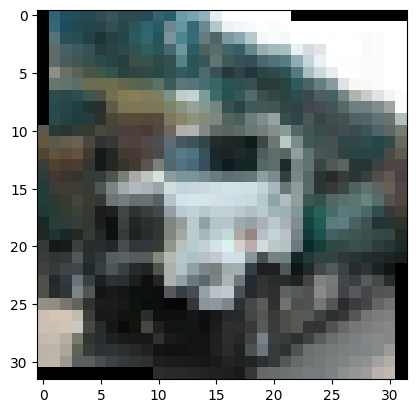

In [81]:
print(labels[35])
plt.imshow(imgs[35].permute(1,2,0)*0.5+0.5)

In [82]:
cls = Classifier().cuda()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    cls.parameters(),
    lr=0.001,
    weight_decay=0.001
)
epochs = 50

In [92]:
best_acc = 0.0
best_model = None

for epoch in range(epochs):
    cls.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(trainloader, desc=f"Epoch {epoch+1}/{epochs}")

    for batch in pbar:
        inputs, labels = batch['img'].cuda(), batch['label'].cuda()

        optimizer.zero_grad()
        outputs = cls(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += preds.eq(labels).sum().item()

        pbar.set_postfix({
            "Loss": f"{running_loss / len(pbar):.3f}",
            "Acc": f"{100. * correct / total:.2f}%"
        })

    if epoch % 10 == 0:
        torch.save(best_model, f"best_cifar_classifier_{epoch}.pth")

    # -------------------------
    # Evaluation
    # -------------------------
    cls.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for batch in testloader:
            inputs, labels = batch['img'].cuda(), batch['label'].cuda()
            outputs = cls(inputs)
            _, preds = outputs.max(1)
            test_total += labels.size(0)
            test_correct += preds.eq(labels).sum().item()

    test_acc = 100. * test_correct / test_total
    print(f"--- Epoch {epoch+1} | Test Acc: {test_acc:.2f}% ---")

    if test_acc > best_acc:
        best_acc = test_acc
        best_model = cls.state_dict()

Epoch 1/50:   0%|          | 0/782 [00:00<?, ?it/s]

--- Epoch 1 | Test Acc: 39.50% ---


Epoch 2/50:   0%|          | 0/782 [00:00<?, ?it/s]

--- Epoch 2 | Test Acc: 47.38% ---


Epoch 3/50:   0%|          | 0/782 [00:00<?, ?it/s]

--- Epoch 3 | Test Acc: 56.76% ---


... (90 outputs left out)

Epoch 49/50:   0%|          | 0/782 [00:00<?, ?it/s]

--- Epoch 49 | Test Acc: 78.58% ---


Epoch 50/50:   0%|          | 0/782 [00:00<?, ?it/s]

--- Epoch 50 | Test Acc: 77.94% ---


In [95]:
# torch.save(cls.state_dict(), "latest_cifar10_cnn_wei.pth")

In [96]:
# torch.save(best_model, "best_cifar10_cnn_wei.pth")